/tmp/ipython-input-3346712186.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2010-01-01')['Close']
[*********************100%***********************]  8 of 8 completed
/tmp/ipython-input-3346712186.py:21: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = data.pct_change()


Date
2010-01-04    NaN
2010-01-05    0.0
2010-01-06    0.0
2010-01-07    0.0
2010-01-08    0.0
             ... 
2025-09-10    1.0
2025-09-11    1.0
2025-09-12    1.0
2025-09-15    1.0
2025-09-16    0.0
Name: SPY, Length: 3950, dtype: float64


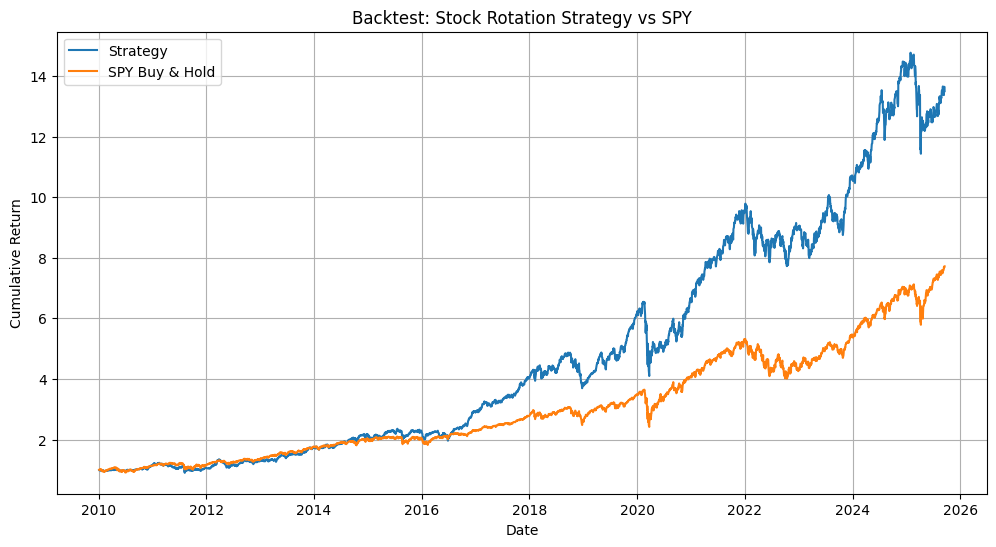


Backtest Results:
Period: 2010-01-05 to 2025-09-16
Total Return - Strategy: 1250.26%
Total Return - SPY: 671.79%
Annualized Return - Strategy: 18.07%
Annualized Return - SPY: 13.93%
Annualized Volatility - Strategy: 20.39%
Annualized Volatility - SPY: 17.29%
Sharpe Ratio - Strategy: 0.89
Sharpe Ratio - SPY: 0.81
Max Drawdown - Strategy: -37.43%
Max Drawdown - SPY: -33.72%


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define tickers: SPY as indicator, AAPL/MSFT (tech), JPM/BAC (financial), NEE (utilities), PG (staples), JNJ (healthcare)
tickers = ['SPY', 'AAPL', 'MSFT', 'JPM', 'BAC', 'NEE', 'PG', 'JNJ']

# Download historical close prices
data = yf.download(tickers, start='2010-01-01')['Close']

# Compute 50-day and 200-day MAs for SPY
spy = data['SPY']
ma50 = spy.rolling(window=50).mean()
ma200 = spy.rolling(window=200).mean()

# Bull signal: 1 if MA50 > MA200 (shifted by 1 day to avoid look-ahead bias), 0 otherwise
signal = (ma50 > ma200).astype(int).shift(1)
print(signal)
# Compute daily returns for all assets
returns = data.pct_change()

# Strategy daily returns:
# - Bull: 50% AAPL + 50% MSFT (tech) + 50% JPM + 50% BAC (financial), equal-weighted
# - Bear: 1/3 NEE + 1/3 PG + 1/3 JNJ (defensive)
bull_ret = 0.25 * (returns['AAPL'] + returns['MSFT'] + returns['JPM'] + returns['BAC'])
bear_ret = (returns['NEE'] + returns['PG'] + returns['JNJ']) / 3
strat_ret = signal * bull_ret + (1 - signal) * bear_ret

# Drop NaN values (from MAs and pct_change)
strat_ret = strat_ret.dropna()
spy_ret = returns['SPY'].loc[strat_ret.index]  # Align SPY returns

# Cumulative returns
cum_strat = (1 + strat_ret).cumprod()
cum_spy = (1 + spy_ret).cumprod()

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cum_strat, label='Strategy')
plt.plot(cum_spy, label='SPY Buy & Hold')
plt.title('Backtest: Stock Rotation Strategy vs SPY')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

# Compute performance metrics
trading_days_per_year = 252
num_days = len(strat_ret)
num_years = num_days / trading_days_per_year

# Annualized return
ann_ret_strat = (cum_strat.iloc[-1] ** (1 / num_years)) - 1
ann_ret_spy = (cum_spy.iloc[-1] ** (1 / num_years)) - 1

# Annualized volatility
ann_vol_strat = strat_ret.std() * np.sqrt(trading_days_per_year)
ann_vol_spy = spy_ret.std() * np.sqrt(trading_days_per_year)

# Sharpe ratio (assuming risk-free rate = 0)
sharpe_strat = ann_ret_strat / ann_vol_strat if ann_vol_strat != 0 else np.nan
sharpe_spy = ann_ret_spy / ann_vol_spy if ann_vol_spy != 0 else np.nan

# Maximum drawdown
def max_drawdown(cum_returns):
    peak = cum_returns.cummax()
    drawdown = (cum_returns - peak) / peak
    return drawdown.min()

mdd_strat = max_drawdown(cum_strat)
mdd_spy = max_drawdown(cum_spy)

# Print results
print("\nBacktest Results:")
print(f"Period: {strat_ret.index[0].date()} to {strat_ret.index[-1].date()}")
print(f"Total Return - Strategy: {cum_strat.iloc[-1] - 1:.2%}")
print(f"Total Return - SPY: {cum_spy.iloc[-1] - 1:.2%}")
print(f"Annualized Return - Strategy: {ann_ret_strat:.2%}")
print(f"Annualized Return - SPY: {ann_ret_spy:.2%}")
print(f"Annualized Volatility - Strategy: {ann_vol_strat:.2%}")
print(f"Annualized Volatility - SPY: {ann_vol_spy:.2%}")
print(f"Sharpe Ratio - Strategy: {sharpe_strat:.2f}")
print(f"Sharpe Ratio - SPY: {sharpe_spy:.2f}")
print(f"Max Drawdown - Strategy: {mdd_strat:.2%}")
print(f"Max Drawdown - SPY: {mdd_spy:.2%}")

/tmp/ipython-input-3547106285.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start='2020-01-01', end='2025-09-04')['Close']
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-3547106285.py:21: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data = data.fillna(method='ffill')



Signal Distribution:
SPY
1.0    959
0.0    465
Name: count, dtype: int64
Percentage of bull signals (1): 67.35%


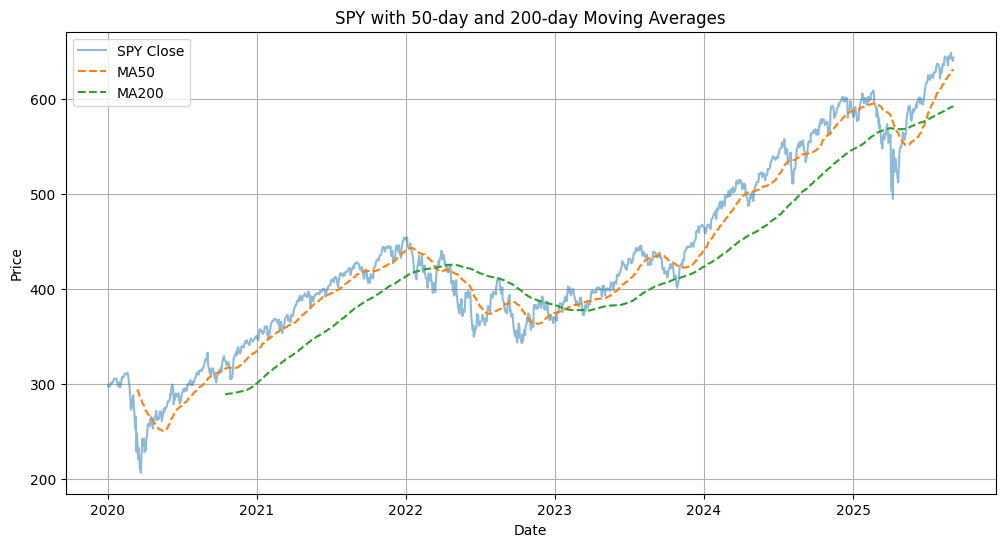

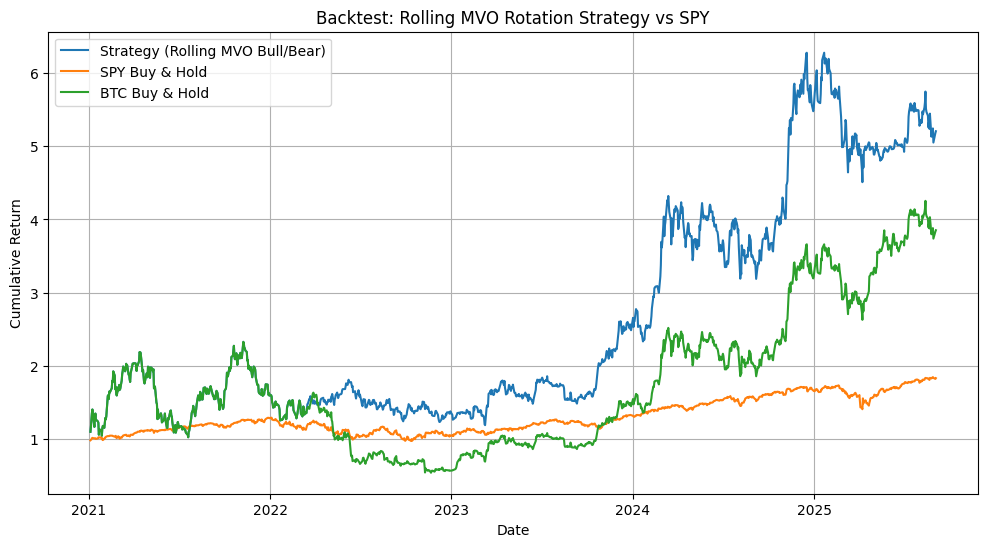


Backtest Results:
Period: 2021-01-04 to 2025-09-03
Total Return - Strategy: 420.26%
Total Return - SPY: 83.40%
Annualized Return - Strategy: 42.56%
Annualized Return - SPY: 13.93%
Annualized Volatility - Strategy: 55.67%
Annualized Volatility - SPY: 17.45%
Sharpe Ratio - Strategy: 0.76
Sharpe Ratio - SPY: 0.80
Max Drawdown - Strategy: -53.06%
Max Drawdown - SPY: -24.50%


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as optimize

# Define tickers: SPY as indicator, bull assets (crypto), bear assets (gold, oil, defensive stocks)
bull_assets = ['BTC-USD']
bear_assets = ['GLD', 'USO', 'EURUSD=X']
tickers = ['SPY'] + bull_assets + bear_assets

# Download historical close prices
data = yf.download(tickers, start='2020-01-01', end='2025-09-04')['Close']

# Filter to only trading days (where SPY has data)
data = data[data['SPY'].notna()]

# Check for missing data in other columns
if data.isnull().any().any():
    print("Warning: Missing data detected. Filling with forward fill.")
    data = data.fillna(method='ffill')

# Compute 50-day and 200-day MAs for SPY
spy = data['SPY']
ma50 = spy.rolling(window=50).mean()
ma200 = spy.rolling(window=200).mean()

# Bull signal: 1 if MA50 > MA200 (shifted by 1 day to avoid look-ahead bias), 0 otherwise
signal = (ma50 > ma200).astype(int).shift(1)

# Diagnostic: Check signal distribution
print("\nSignal Distribution:")
print(signal.value_counts())
print(f"Percentage of bull signals (1): {signal.mean() * 100:.2f}%")

# Diagnostic: Plot MAs to visualize crossovers
plt.figure(figsize=(12, 6))
plt.plot(spy, label='SPY Close', alpha=0.5)
plt.plot(ma50, label='MA50', linestyle='--')
plt.plot(ma200, label='MA200', linestyle='--')
plt.title('SPY with 50-day and 200-day Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

# Compute daily returns for all assets
returns = data.pct_change()

# Function to optimize portfolio (max Sharpe, rf=0, long-only)
def optimize_portfolio(returns_port, rf=0.0):
    mean = returns_port.mean() * 252
    cov = returns_port.cov() * 252
    num_assets = len(returns_port.columns)

    def neg_sharpe(w):
        port_ret = np.dot(w, mean)
        port_vol = np.sqrt(np.dot(w.T, np.dot(cov, w)))
        return - (port_ret - rf) / port_vol if port_vol > 0 else 0

    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
    bounds = tuple((0, 1) for _ in range(num_assets))
    init = np.array([1. / num_assets] * num_assets)
    res = optimize.minimize(neg_sharpe, init, method='SLSQP', bounds=bounds, constraints=constraints)
    if res.success:
        return res.x
    else:
        return init  # fallback to equal weights

# Strategy daily returns: rolling MVO with 1-year lookback
strat_ret = pd.Series(index=returns.index, dtype=float)
lookback = 252

for i in range(lookback, len(returns)):
    if pd.isna(signal.iloc[i]):
        continue

    if signal.iloc[i] == 1:
        ret_port = returns[bull_assets].iloc[i - lookback:i].dropna(how='any')
        if len(ret_port) < lookback:
            continue
        w_bull = optimize_portfolio(ret_port)
        strat_ret.iloc[i] = np.dot(returns[bull_assets].iloc[i], w_bull)
    else:
        ret_port = returns[bear_assets].iloc[i - lookback:i].dropna(how='any')
        if len(ret_port) < lookback:
            continue
        w_bear = optimize_portfolio(ret_port)
        strat_ret.iloc[i] = np.dot(returns[bear_assets].iloc[i], w_bear)

# Drop NaN values
strat_ret = strat_ret.dropna()
spy_ret = returns['SPY'].loc[strat_ret.index]  # Align SPY returns
btc_ret = returns['BTC-USD'].loc[strat_ret.index]  # Align BTC-USD returns

# Cumulative returns
cum_strat = (1 + strat_ret).cumprod()
cum_spy = (1 + spy_ret).cumprod()
cum_btc = (1 + btc_ret).cumprod()
# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cum_strat, label='Strategy (Rolling MVO Bull/Bear)')
plt.plot(cum_spy, label='SPY Buy & Hold')
plt.plot(cum_btc, label='BTC Buy & Hold')
plt.title('Backtest: Rolling MVO Rotation Strategy vs SPY')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

# Compute performance metrics
trading_days_per_year = 252
num_days = len(strat_ret)
num_years = num_days / trading_days_per_year

# Annualized return
ann_ret_strat = (cum_strat.iloc[-1] ** (1 / num_years)) - 1
ann_ret_spy = (cum_spy.iloc[-1] ** (1 / num_years)) - 1

# Annualized volatility
ann_vol_strat = strat_ret.std() * np.sqrt(trading_days_per_year)
ann_vol_spy = spy_ret.std() * np.sqrt(trading_days_per_year)

# Sharpe ratio (assuming risk-free rate = 0)
sharpe_strat = ann_ret_strat / ann_vol_strat if ann_vol_strat != 0 else np.nan
sharpe_spy = ann_ret_spy / ann_vol_spy if ann_vol_spy != 0 else np.nan

# Maximum drawdown
def max_drawdown(cum_returns):
    peak = cum_returns.cummax()
    drawdown = (cum_returns - peak) / peak
    return drawdown.min()

mdd_strat = max_drawdown(cum_strat)
mdd_spy = max_drawdown(cum_spy)

# Print results
print("\nBacktest Results:")
print(f"Period: {strat_ret.index[0].date()} to {strat_ret.index[-1].date()}")
print(f"Total Return - Strategy: {cum_strat.iloc[-1] - 1:.2%}")
print(f"Total Return - SPY: {cum_spy.iloc[-1] - 1:.2%}")
print(f"Annualized Return - Strategy: {ann_ret_strat:.2%}")
print(f"Annualized Return - SPY: {ann_ret_spy:.2%}")
print(f"Annualized Volatility - Strategy: {ann_vol_strat:.2%}")
print(f"Annualized Volatility - SPY: {ann_vol_spy:.2%}")
print(f"Sharpe Ratio - Strategy: {sharpe_strat:.2f}")
print(f"Sharpe Ratio - SPY: {sharpe_spy:.2f}")
print(f"Max Drawdown - Strategy: {mdd_strat:.2%}")
print(f"Max Drawdown - SPY: {mdd_spy:.2%}")